1. Use default sample values
2. Enter custom values


Select an option (1 or 2):  1



Using default sample values...

         RESOURCE ALLOCATION MODULE          

 SELECTED ITEMS & ALLOCATION DETAILS:
Item Name       | Allocated Weight   | Fraction Taken  | Profit Contribution 
---------------------------------------------------------------------------
Resource_A      | 10.00              | 1.00            | 60.00               
Resource_B      | 20.00              | 1.00            | 100.00              
Resource_C      | 20.00              | 0.67            | 80.00               

 MAXIMUM ACHIEVABLE PROFIT:
Total Profit = 240.00

 DYNAMIC PERFORMANCE METRICS (THIS RUN):
Input Size (N)         : 3 items
Measured Execution Time : 45.00 microseconds
Tracked Object Memory  : 224 bytes

         DYNAMIC GREEDY SCALING TABLE (EMPIRICAL COMPLEXITY)          
Input Size (N)   | Execution Time (µs)    | Memory Allocated (Bytes)
-----------------------------------------------------------------------
3                | 45.00                  | 224                      <-- (Y

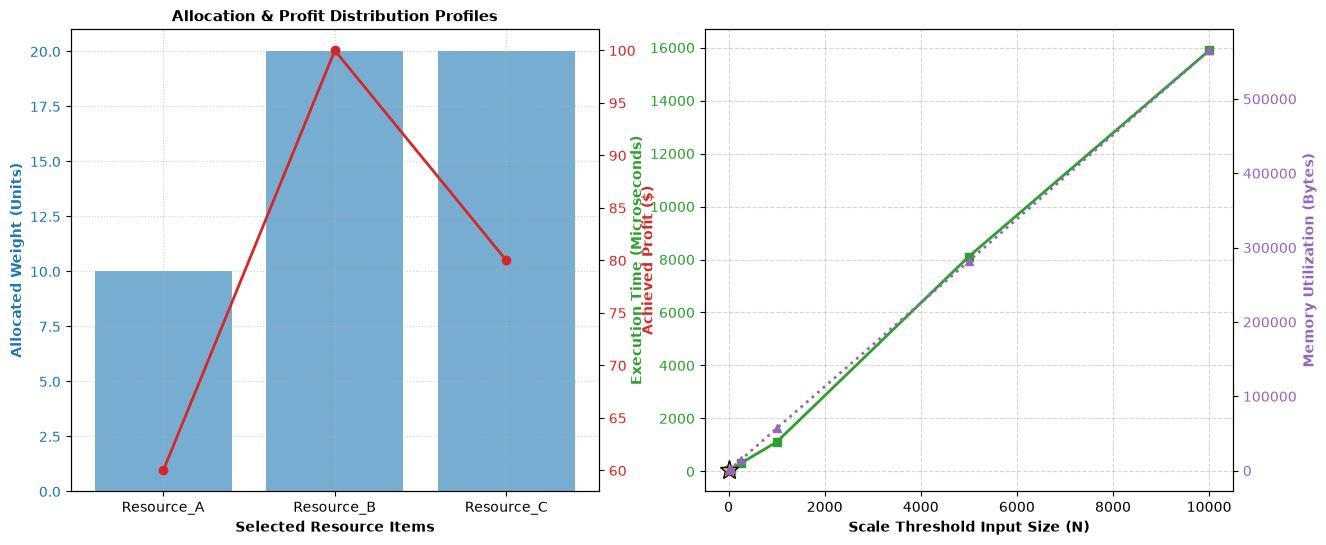

In [2]:
import time
import sys
import random
import matplotlib.pyplot as plt

class Item:
    def __init__(self, name, profit, weight):
        self.name = name
        self.profit = profit
        self.weight = weight
        self.ratio = profit / weight

def fractional_knapsack(capacity, items):
    sorted_items = sorted(items, key=lambda x: x.ratio, reverse=True)
    total_profit = 0.0
    allocation_details = []
    
    for item in sorted_items:
        if capacity == 0:
            break
            
        if item.weight <= capacity:
            capacity -= item.weight
            total_profit += item.profit
            allocation_details.append({
                "item": item.name,
                "allocated_weight": item.weight,
                "fraction": 1.0,
                "achieved_profit": item.profit
            })
        else:
            fraction = capacity / item.weight
            partial_profit = item.profit * fraction
            total_profit += partial_profit
            allocation_details.append({
                "item": item.name,
                "allocated_weight": capacity,
                "fraction": fraction,
                "achieved_profit": partial_profit
            })
            capacity = 0
            
    return total_profit, allocation_details

def run_empirical_benchmark(current_n, current_time, current_mem):
    benchmarks = []
    test_sizes = [10, 50, 250, 1000, 5000, 10000]
    
    if current_n not in test_sizes:
        test_sizes.append(current_n)
    test_sizes.sort()
    
    for size in test_sizes:
        if size == current_n:
            benchmarks.append((size, current_time, current_mem))
            continue
            
        test_pool = [Item(f"R_{i}", random.uniform(10, 500), random.uniform(5, 100)) for i in range(size)]
        test_capacity = size * 25
        
        t_start = time.perf_counter_ns()
        fractional_knapsack(test_capacity, test_pool)
        t_end = time.perf_counter_ns()
        
        exec_time_us = (t_end - t_start) / 1000
        mem_bytes = sys.getsizeof(test_pool) + sum(sys.getsizeof(it) for it in test_pool)
        
        benchmarks.append((size, exec_time_us, mem_bytes))
        
    return benchmarks

if __name__ == "__main__":
    print("1. Use default sample values")
    print("2. Enter custom values")
    choice = input("Select an option (1 or 2): ").strip()
    
    if choice == "2":
        knapsack_capacity = float(input("Enter maximum knapsack capacity: "))
        num_items = int(input("Enter the number of items: "))
        resource_pool = []
        for i in range(num_items):
            print(f"\n--- Item {i+1} ---")
            name = input("Enter item name: ")
            profit = float(input("Enter item profit: "))
            weight = float(input("Enter item weight: "))
            resource_pool.append(Item(name, profit, weight))
    else:
        print("\nUsing default sample values...")
        knapsack_capacity = 50
        resource_pool = [
            Item("Resource_A", profit=60, weight=10),
            Item("Resource_B", profit=100, weight=20),
            Item("Resource_C", profit=120, weight=30)
        ]
    
    start_time = time.perf_counter_ns()
    max_profit, allocations = fractional_knapsack(knapsack_capacity, resource_pool)
    end_time = time.perf_counter_ns()
    
    execution_time_us = (end_time - start_time) / 1000
    memory_used_bytes = sys.getsizeof(resource_pool) + sum(sys.getsizeof(item) for item in resource_pool)
    
    print("\n=============================================")
    print("         RESOURCE ALLOCATION MODULE          ")
    print("=============================================")
    print("\n SELECTED ITEMS & ALLOCATION DETAILS:")
    print(f"{'Item Name':<15} | {'Allocated Weight':<18} | {'Fraction Taken':<15} | {'Profit Contribution':<20}")
    print("-" * 75)
    for alloc in allocations:
        print(f"{alloc['item']:<15} | {alloc['allocated_weight']:<18.2f} | {alloc['fraction']:<15.2f} | {alloc['achieved_profit']:<20.2f}")
        
    print("\n MAXIMUM ACHIEVABLE PROFIT:")
    print(f"Total Profit = {max_profit:.2f}")
    print("\n DYNAMIC PERFORMANCE METRICS (THIS RUN):")
    print(f"Input Size (N)         : {len(resource_pool)} items")
    print(f"Measured Execution Time : {execution_time_us:.2f} microseconds")
    print(f"Tracked Object Memory  : {memory_used_bytes} bytes")
    print("=============================================")

    benchmark_data = run_empirical_benchmark(len(resource_pool), execution_time_us, memory_used_bytes)
    
    print("\n=======================================================================")
    print("         DYNAMIC GREEDY SCALING TABLE (EMPIRICAL COMPLEXITY)          ")
    print("=======================================================================")
    print(f"{'Input Size (N)':<16} | {'Execution Time (µs)':<22} | {'Memory Allocated (Bytes)':<24}")
    print("-" * 71)
    for b_size, b_time, b_mem in benchmark_data:
        marker = " <-- (Your Run)" if b_size == len(resource_pool) else ""
        print(f"{b_size:<16} | {b_time:<22.2f} | {b_mem:<24}{marker}")
    print("=======================================================================\n")

    names = [alloc["item"] for alloc in allocations]
    weights = [alloc["allocated_weight"] for alloc in allocations]
    profits = [alloc["achieved_profit"] for alloc in allocations]

    fig, (ax_alloc, ax_scale) = plt.subplots(1, 2, figsize=(15, 6))

    color_bar = '#1f77b4'
    ax_alloc.set_xlabel('Selected Resource Items', fontweight='bold')
    ax_alloc.set_ylabel('Allocated Weight (Units)', color=color_bar, fontweight='bold')
    ax_alloc.bar(names, weights, color=color_bar, alpha=0.6, label='Weight Allocated')
    ax_alloc.tick_params(axis='y', labelcolor=color_bar)
    ax_alloc.grid(True, linestyle=':', alpha=0.6)

    ax_alloc_twin = ax_alloc.twinx()  
    color_line = '#d62728'
    ax_alloc_twin.set_ylabel('Achieved Profit ($)', color=color_line, fontweight='bold')
    ax_alloc_twin.plot(names, profits, color=color_line, marker='o', linewidth=2, label='Profit Achieved')
    ax_alloc_twin.tick_params(axis='y', labelcolor=color_line)
    ax_alloc.set_title('Allocation & Profit Distribution Profiles', fontsize=11, fontweight='bold')

    b_sizes = [row[0] for row in benchmark_data]
    b_times = [row[1] for row in benchmark_data]
    b_mems  = [row[2] for row in benchmark_data]

    color_time = '#2ca02c'
    ax_scale.set_xlabel('Scale Threshold Input Size (N)', fontweight='bold')
    ax_scale.set_ylabel('Execution Time (Microseconds)', color=color_time, fontweight='bold')
    ax_scale.plot(b_sizes, b_times, color=color_time, marker='s', linestyle='-', linewidth=2, label='Time')
    ax_scale.tick_params(axis='y', labelcolor=color_time)
    ax_scale.grid(True, linestyle='--', alpha=0.5)

    ax_scale_twin = ax_scale.twinx()
    color_mem = '#9467bd'
    ax_scale_twin.set_ylabel('Memory Utilization (Bytes)', color=color_mem, fontweight='bold')
    ax_scale_twin.plot(b_sizes, b_mems, color=color_mem, marker='^', linestyle=':', linewidth=2, label='Memory')
    ax_scale_twin.tick_params(axis='y', labelcolor=color_mem)
    
    ax_scale.plot(len(resource_pool), execution_time_us, marker='*', color='gold', markersize=14, markeredgecolor='black')